# **Tensors**

텐서는 배열이나 행렬과 매우 비슷한 특수한 자료구조이다.
PyTorch에서는 모델의 입력·출력은 물론 모델의 파라미터까지 모두 텐서로 표현한다.

NumPy의 ndarray와 거의 같지만 두 가지가 결정적으로 다르다.

1. **GPU/가속기에서 실행 가능**

- CPU 외에 GPU 같은 하드웨어 가속기 위에서 돌릴 수 있다.
- CPU 상에서는 NumPy 배열과 메모리를 공유해서 복사 없이 주고받을 수도 있다.

2. **자동미분(autograd)에 최적화**
- 역전파를 위한 계산 그래프를 텐서가 스스로 기록한다.

In [ ]:
import torch
import numpy as np

# **1.Tensor 만들기**

텐서는 다양한 방법으로 초기화 할 수 있다.

**1. 파이썬 변수로 직접 만들기**

In [ ]:
data = [[1, 2],[3, 4]]
x_data = torch.tensor(data)
type(x_data)

torch.Tensor

**2. Numpy array로 만들기**

In [ ]:
np_array = np.array(data)
x_np = torch.from_numpy(np_array)

**3. 다른 텐서로 만들기**


In [ ]:
x_ones = torch.ones_like(x_data) # x_data의 속성 유지
print(f"Ones Tensor: \n {x_ones} \n")

Ones Tensor: 
 tensor([[1, 1],
        [1, 1]]) 



In [ ]:
x_rand = torch.rand_like(x_data, dtype=torch.float) # dtype만 덮어쓰기
print(f"Random Tensor: \n {x_rand} \n")

Random Tensor: 
 tensor([[0.5358, 0.3478],
        [0.3578, 0.9875]]) 



**4. shape만 주고 랜덤/상수로**

In [ ]:
shape = (2,3)
rand_tensor = torch.rand(shape)
ones_tensor = torch.ones(shape)
zeros_tensor = torch.zeros(shape)

print(f"Random Tensor: \n {rand_tensor} \n")
print(f"Ones Tensor: \n {ones_tensor} \n")
print(f"Zeros Tensor: \n {zeros_tensor}")

Random Tensor: 
 tensor([[0.3434, 0.5844, 0.5097],
        [0.4089, 0.6047, 0.8837]]) 

Ones Tensor: 
 tensor([[1., 1., 1.],
        [1., 1., 1.]]) 

Zeros Tensor: 
 tensor([[0., 0., 0.],
        [0., 0., 0.]])


# **2.Tensor의 속성**

텐서의 속성은 모양(shape), 자료형(dtype), 저장된 장치(device)를 나타낸다.

[참고] 각 속성에서 자주 보게 되는 에러는 다음과 같다.
* shape 안맞으면 : 행렬곱 에러
* dtype 안맞으면 : `expected Float but found Long`
* device 안맞으면 : `expected all tensors to be on the same device`

In [ ]:
tensor = torch.rand(3,4)
print(tensor)
print(f"Shape of tensor: {tensor.shape}")
print(f"Datatype of tensor: {tensor.dtype}")
print(f"Device tensor is stored on: {tensor.device}")

tensor([[0.5521, 0.4706, 0.6741, 0.6649],
        [0.3383, 0.9384, 0.2303, 0.0515],
        [0.2886, 0.3699, 0.1412, 0.9477]])
Shape of tensor: torch.Size([3, 4])
Datatype of tensor: torch.float32
Device tensor is stored on: cpu


# **3. Tensor 연산**

산술, 선형대수, 행렬조작(전치/인덱싱/슬라이싱), 샘플링등 1200개가 넘는 연산이 제공된다.

- [모든 연산자 확인하기](https://pytorch.org/docs/stable/torch.html).

기본적으로 tensor는 CPU에 생성된다.
- 가속기 (CUDA, GPU, XPU, TPU 등)에서 tensor연산이 필요한 경우에는 `.to` method로 복사하여 사용해야 한다.
- 큰 tensor를 자주 옮기는 연산은 당연히 시간, 메모리상으로 손해이니 필요할때만 옮기자!*






직접 위치를 확인해보기 위해 colab runtime을 GPU로 바꿔보자.

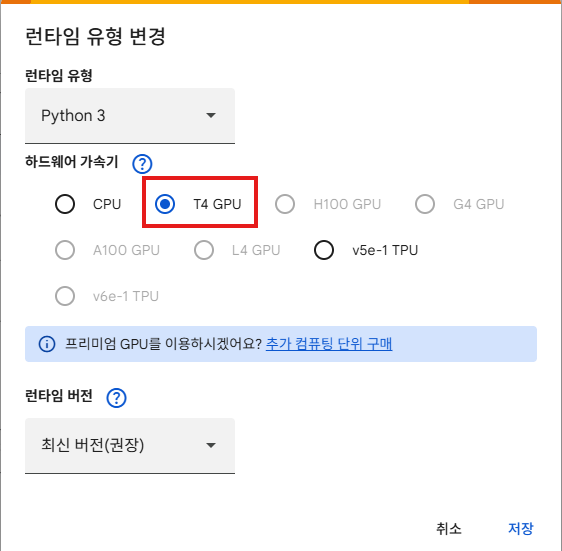

---



In [ ]:
print(f"Device tensor is stored on: {tensor.device}")

if torch.accelerator.is_available():
    tensor = tensor.to(torch.accelerator.current_accelerator())

print(f"Device tensor is stored on: {tensor.device}")

Device tensor is stored on: cpu
Device tensor is stored on: cuda:0


##  **1. 인덱싱과 슬라이싱**

Numpy와 거의 동일하다.

- ...(Ellipsis)은 "앞쪽 차원은 전부"라는 뜻이다.
 - 2차원에서는 [:, -1]과 같지만, 4차원 이미지 배치에서는 [..., -1]이 훨씬 안전하게 사용 가능하다.

In [ ]:
tensor = torch.ones(4, 4)
print(f"First row: {tensor[0]}")
print(f"First column: {tensor[:, 0]}")
print(f"Last column: {tensor[..., -1]}")
tensor[:,1] = 0
print(tensor)

First row: tensor([1., 1., 1., 1.])
First column: tensor([1., 1., 1., 1.])
Last column: tensor([1., 1., 1., 1.])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


## **2. 이어붙이기**

* dim = 1 : 가로 방향으로 쌓인다.
* dim = 0 : 세로로 쌓인다.

In [ ]:
t1 = torch.cat([tensor, tensor, tensor], dim=1)
print(t1)

tensor([[1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.]])


## **3. 산술연산**

### **3-1) 행렬곱**
- 행렬곱은 **앞행렬의 열개수 = 뒤행렬의 행 개수** 여야 연산가능함

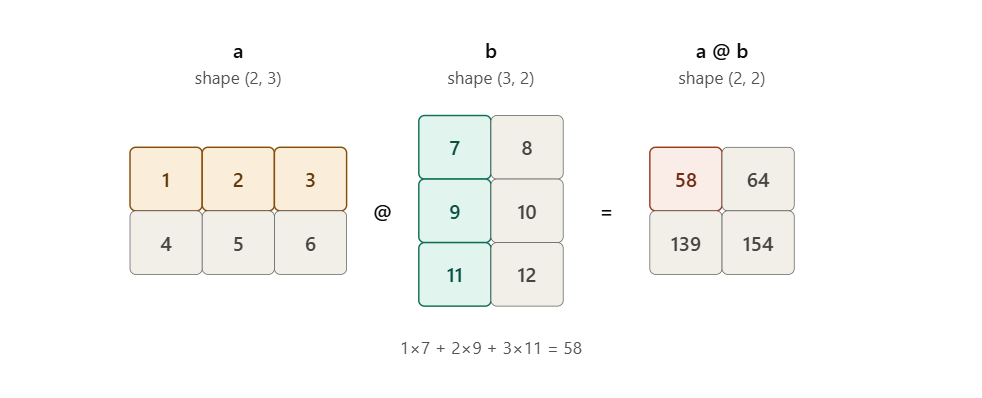

In [ ]:
# 세줄 모두 같은 결과
# ``tensor.T`` 는  tensor의 전치행렬
y1 = tensor @ tensor.T
y2 = tensor.matmul(tensor.T)
y3 = torch.rand_like(y1)
torch.matmul(tensor, tensor.T, out=y3)

print(y1)
print(y2)
print(y3)

tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])
tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])
tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])


**[참고]** 전치행렬 : 행렬의 열과 행을 교환한 행렬

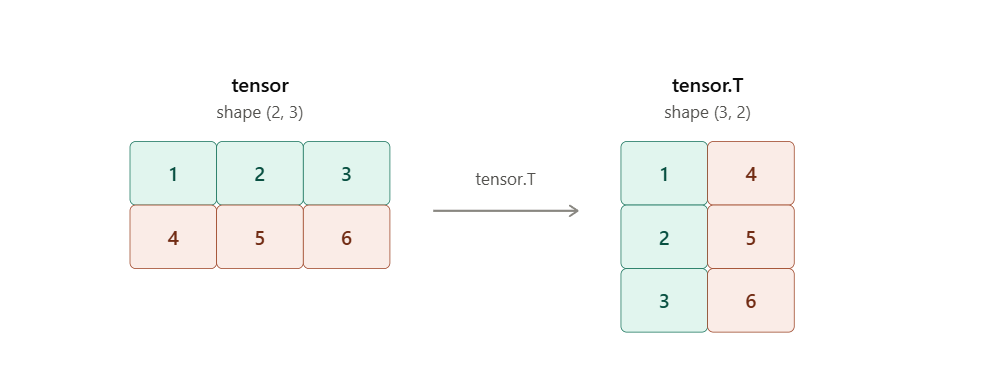

### **3-2) 요소별 곱**

'*' 연산은 요소별곱을 위한 연산자이다.
- shape이 같아야만 연산가능하다.
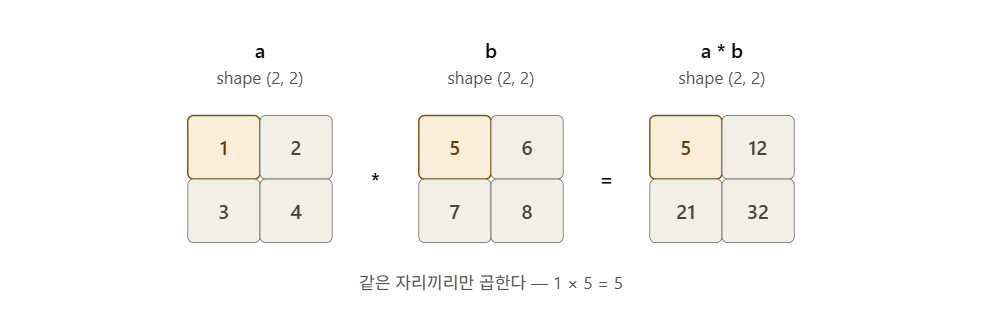

In [ ]:
# 세줄 모두 같은 결과
z1 = tensor * tensor
z2 = tensor.mul(tensor)
z3 = torch.rand_like(tensor)
torch.mul(tensor, tensor, out=z3)

print(z1)
print(z2)
print(z3)

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


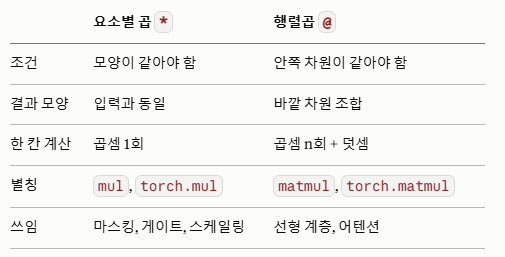

## **4. 숫자로 변환**

'.item' method를 이용하여 단일요소 tensor(tensor안에 숫자 딱 하나 있는경우)에서 python 숫자로 변경가능하다
* loss 값을 기록할 때 반드시 사용하자. -> tensor째로 list에 때려넣으면 메모리를 많이 차지한다.

In [ ]:
agg = tensor.sum() #tensor안의 모든 요소를 다 더한다.
print(agg, type(agg)) #여전히 tensor인 상태

agg_item = agg.item() #.item()으로 숫자로 변환한다.
print(agg_item, type(agg_item))

tensor(12.) <class 'torch.Tensor'>
12.0 <class 'float'>


## **5. In-place 연산**
연산결과를 이전객체에 그대로 저장하는 연산을 In-place 연산이라고 한다.
- pytorch에서는 연산자 이름뒤에 `_`가 붙는다.

```
#y를 복사해서 x에 저장
x.copy_(y)

#x를 전치해서 x에 저장
x.t_()  
```

In-place 연산은 메모리를 아껴준다. (객체 생성을 새로 안하고 덮어쓰기 때문)
- 하지만 이력이 즉시 사라지기 때문에 미분계산시 문제가 될 수 있어 사용을 권장하지 않는다.



In [ ]:
print(f"{tensor} \n")
tensor.add_(5)
print(tensor)

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]]) 

tensor([[6., 5., 6., 6.],
        [6., 5., 6., 6.],
        [6., 5., 6., 6.],
        [6., 5., 6., 6.]])


# **4. Numpy와의 연관**

CPU에 있는 텐서와 NumPy 배열은 메모리 위치를 공유할 수 있다.
- 한쪽을 바꾸면 다른쪽도 바뀐다.

### **Tensor -> NumPy**


In [ ]:
t = torch.ones(5)
print(f"t: {t}")
n = t.numpy()
print(f"n: {n}")

t: tensor([1., 1., 1., 1., 1.])
n: [1. 1. 1. 1. 1.]


**tensor 변경시 numpy 배열 변경**


In [ ]:
t.add_(1)
print(f"t: {t}")
print(f"n: {n}")

t: tensor([2., 2., 2., 2., 2.])
n: [2. 2. 2. 2. 2.]


### **Numpy -> Tensor**


In [ ]:
n = np.ones(5)
t = torch.from_numpy(n)

**numpy 배열 변경시 tensor변경**

In [ ]:
np.add(n, 1, out=n)
print(f"t: {t}")
print(f"n: {n}")